# 13. Optimization

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In Exercise 12.3 in the previous chapter you were asked to find the best launch angle for a human cannonball, meaning the angle that maximizes the distance traveled before landing. This kind of problem, finding minimums and maximums, is called *optimization*.

In this chapter, we’ll solve a similar problem, finding the best launch angle for a baseball. We’ll solve the problem two ways, first running simulations with a range of values and plotting the results, then using a MATLAB function that automates the process, `fminsearch`.

## Optimal Baseball

In the previous chapter we wrote functions to simulate the flight of a baseball with a known initial velocity. Now we’ll use that code to find the launch angle that maximizes *range*, that is, the distance the ball travels before landing.

First, we need an event function to stop the simulation when the ball lands.

This chapter uses the baseball model with drag from Chapter 12. Run this cell first: it defines the rate function and its helpers.

In [ ]:
% The baseball model from Chapter 12 (code/chap13/baseball3.m)
function res = rate_func(t, W)
    P = W(1:2);
    V = W(3:4);

    dPdt = V;
    dVdt = acceleration(t, P, V);

    res = [dPdt; dVdt];
end

function res = acceleration(t, P, V)
    g = 9.8;                       % acceleration of gravity in m/s^2
    a_gravity = [0; -g];

    m = 0.145;                     % mass in kilograms
    a_drag = drag_force(V) / m;
    res = a_gravity + a_drag;
end

function res = drag_force(V)
    C_d = 0.3;      % dimensionless
    rho = 1.3;      % kg / m^3
    A = 0.0042;     % m^2
    v = norm(V);    % m/s

    res = - 1/2 * C_d * rho * A * v * V;
end

In [ ]:
function [value, isterminal, direction] = event_func(t, W)
    value = W(2);
    isterminal = 1;
    direction = -1;
end

This is similar to the event function we saw in Section 11.3, except that it uses `W(2)` as the event value, which is the y-coordinate. This event function stops the simulation when the altitude of the ball is 0 and falling.

Now we can call `ode45` like this:

In [ ]:
P = [0; 1];       % initial position in m
V = [40; 30];     % initial velocity in m/s
W = [P; V];       % initial condition

tspan = [0 10];
options = odeset('Events', @event_func);
[T, M] = ode45(@rate_func, tspan, W, options);

The initial position of the ball is 1 m above home plate. The ball’s initial velocity is 40 m/s in the $x$-direction and 30 m/s in the $y$-direction.

The maximum duration of the simulation is 10 s, but we expect an event to stop the simulation first. We can get the final values of the simulation like this:

In [ ]:
T(end)
M(end, :)

The final time is 5.1 s. The final $x$-position is 131 m; the final $y$-position is 0, as expected.

## Trajectory

Now we can extract the $x$- and $y$-positions:

In [ ]:
X = M(:, 1);
Y = M(:, 2);

In Section 12.3 we plotted `X` and `Y` separately as functions of time. As an alternative, we can plot them against each other, like this:

In [ ]:
plot(X, Y)

Figure 13.1 shows the result, which is the *trajectory* of the baseball from launch, on the left, to landing, on the right.

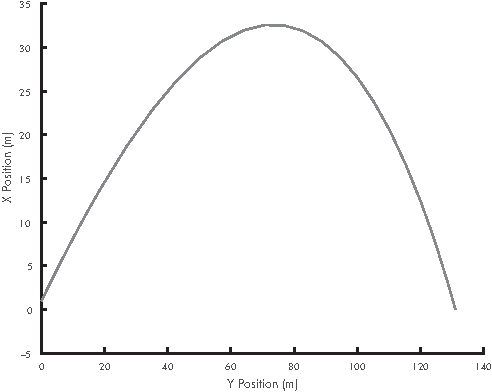

*Figure 13.1: Simulated flight of a baseball plotted as a trajectory*

## Range Versus Angle

Now we’ll simulate the trajectory of the baseball with a range of launch angles. First, we’ll take the code we have and wrap it in a function that takes the launch angle as an input variable, runs the simulation, and returns the distance the ball travels (Listing 13.1).

*Listing 13.1: A function that takes the launch angle of a baseball and returns the distance it travels*

In [ ]:
function res = baseball_range(theta)
    P = [0; 1];
    v = 50;
    [vx, vy] = pol2cart(theta, v);

    V = [vx; vy];     % initial velocity in m/s
    W = [P; V];       % initial condition

    tspan = [0 10];
    options = odeset('Events', @event_func);
    [T, M] = ode45(@rate_func, tspan, W, options);

    res = M(end, 1);
end

The launch angle, `theta`, is in radians. The magnitude of velocity, `v`, is always 50 m/s. We use `pol2cart` to convert the angle and magnitude (*polar* coordinates) to Cartesian components, `vx` and `vy`.

After running the simulation we extract the final $x$-position and return it as an output variable.

We can run this function for a range of angles like this:

In [ ]:
thetas = linspace(0, pi/2);
for i = 1:length(thetas)
    ranges(i) = baseball_range(thetas(i));
end

And then plot `ranges` as a function of `thetas`:

In [ ]:
plot(thetas, ranges)

Figure 13.2 shows the result. As expected, the ball does not travel far if it’s hit nearly horizontal or vertical. The peak is apparently near 0.7 rad.

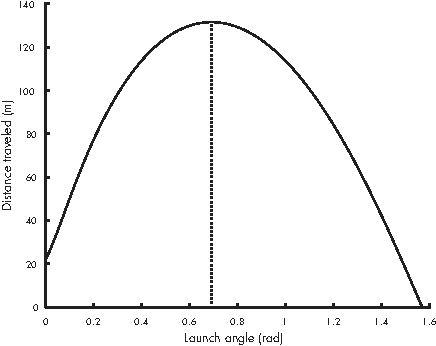

*Figure 13.2: Range of a baseball as a function of launch angle*

Considering that our model is only approximate, this result might be good enough. But if we want to find the peak more precisely, we can use `fminsearch`.

## fminsearch

The `fminsearch` function is similar to `fzero`, which we saw in Chapter 7. Recall that `fzero` takes a function handle and an initial guess, and it returns a root of the function. As an example, to find a root of the function

In [ ]:
function res = error_func(x)
    res = x^2 - 2;
end

we can call `fzero` like this:

In [ ]:
x = fzero(@error_func, 1)

The result is near the square root of 2. Let’s call `fminsearch` with the same function:

In [ ]:
x = fminsearch(@error_func, 1)

The result is close to 0, which is where this function is minimized. Optionally, `fminsearch` returns two values:

In [ ]:
[x, fval] = fminsearch(@error_func, 1)

The `x` is the location of the minimum, and `fval` is the value of the function evaluated at `x`.

If we want to find the maximum of a function, rather than the minimum, we can still use `fminsearch` by writing a short function that negates the function we want to maximize. In the baseball example, the function we want to maximize is `baseball_range`; we can wrap it in another function like this:

In [ ]:
function res = min_func(angle)
    res = -baseball_range(angle);
end

And then we call `fminsearch` like this:

In [ ]:
[x, fval] = fminsearch(@min_func, pi/4)

The optimal launch angle for the baseball is 0.69 rad; launched at that angle, the ball travels almost 132 m.

If you’re curious about how `fminsearch` works, see “How fminsearch Works” in Section 15.3.

## Animation

Animation is a useful tool for checking the results of a physical model. If something is wrong, animation can make it obvious. There are two ways to do animation in MATLAB. One is to use `getframe` to capture a series of images and then use `movie` to play them back.

The more informal way is to draw a series of plots. Listing 13.2 is a function that animates the results of a baseball simulation:

*Listing 13.2: A function that animates the results of a baseball simulation*

In [ ]:
function animate(T,M)
    X = M(:,1);
    Y = M(:,2);

    minmax = [min([X]), max([X]), min([Y]), max([Y])];

    for i=1:length(T)
        clf; hold on
        axis(minmax)
        plot(X(i), Y(i), 'o')
        drawnow;

        if i < length(T)
            dt = T(i+1) - T(i);
            pause(dt);
        end
    end
end

The input variables are the output from `ode45`: `T`, which contains the time values, and `M`, which contains the position and velocity of the baseball.

A vector of four elements, `minmax` is used inside the loop to set the axes of the figure. This is necessary because otherwise MATLAB scales the figure each time through the loop, so the axes keep changing, which makes the animation hard to watch.

Each time through the loop, `animate` uses `clf` to clear the figure and `axis` to reset the axes. Then it plots a circle to represent the position of the baseball.

We have to call `drawnow` after `plot` so that MATLAB actually displays each plot. Otherwise it waits until you finish drawing all the figures and then updates the display.

We can call `animate` like this:

```
tspan = [0 10];
W = [0 1 40 30];
[T, M] = ode45(@rate_func, tspan, W);
animate(T, M)
```

*In the browser version of Octave, plots don't update while a cell runs, so the animation can't play here; it works in MATLAB and desktop Octave. Instead, the next cell draws a still picture of what the animation shows: the ball's position every 0.1 s.*

In [ ]:
% A still picture of the animation (not in the book): the position every 0.1 s
tspan = 0:0.1:10;
W = [0 1 40 30];
options = odeset('Events', @event_func);
[T, M] = ode45(@rate_func, tspan, W, options);
plot(M(:, 1), M(:, 2), 'o')
xlabel('x position (m)')
ylabel('y position (m)')

One limitation of this kind of animation is that the speed of the animation depends on how fast your computer can generate the plots. Since the results from `ode45` are usually not equally spaced in time, your animation might slow down where `ode45` takes small time steps and speed up where the time steps are larger.

One way to fix this problem is to change the way we specify `tspan`. Here’s an example:

In [ ]:
tspan = 0:0.1:10;

The result is a vector that goes from 0 to 10 with a step size of 0.1. Passing `tspan` to `ode45` in this form doesn’t affect the accuracy of the results; `ode45` still uses variable time steps to generate the estimates, but then it interpolates them before returning the results.

With equal time steps, the animation should be smoother.

Another option is to use `pause` to play the animation in real time. After drawing each frame and calling `drawnow`, you can compute the time until the next frame and use `pause` to wait:

```
dt = T(i+1) - T(i);
pause(dt);
```

A limitation of this method is that it ignores the time required to draw the figure, so it tends to run slow, especially if the figure is complex or the time step is small.

## Chapter Review

This chapter presented two new tools, `fminsearch` and `animate`. The MATLAB function `fminsearch` searches efficiently for the minimum of a function and can be adapted to search for the maximum, too. The `animate` function is one I wrote to read results from `ode45` and generate an animation; the version in this chapter works with the results from the baseball simulation, but it can be adapted for other simulations.

In the exercises below, you have a chance to extend the example from this chapter and bring together many of the tools we have used so far.

In the next chapter, we move on to a new example, celestial mechanics, which describes the motion of planets and other bodies in outer space.

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise.**

Manny Ramirez is a former member of the Boston Red Sox who was famous for his relaxed attitude. The goal of this exercise is to solve the following Manny-inspired problem:

> What is the minimum effort required to hit a home run in Fenway Park?

Fenway Park is a baseball stadium in Boston, Massachusetts. One of its most famous features is the “Green Monster,” which is a wall in left field that is unusually close to home plate, only 310 feet away. To compensate for the short distance, the wall is unusually high, at 37 feet.

You can solve this problem in two steps:

1.  For a given velocity, find the launch angle that maximizes the height of the ball when it reaches the wall. Notice that this is not quite the same as the angle that maximizes the distance the ball travels.

2.  Find the minimal velocity that clears the wall, given that it has the optimal launch angle. Hint: this is actually a root-finding problem, not an optimization problem.

**Exercise.**

A golf ball hit with backspin generates lift, which might increase the distance it travels, but the energy that goes into generating spin probably comes at the cost of lower initial velocity.

Write a simulation of the flight of a golf ball and use it to find the launch angle and allocation of spin and initial velocity (for a fixed energy budget) that maximizes the horizontal range of the ball in the air.

The lift of a spinning ball is due to the Magnus force (see <https://greenteapress.com/matlab/magnus>), which is perpendicular to the axis of spin and the path of flight. The coefficient of lift is proportional to the spin rate; for a ball spinning at 3000 rpm it is about 0.1. The coefficient of drag of a golf ball is about 0.2 as long as the ball is moving faster than 20 m/s.

In [ ]:
% Solution

% Solve the Manny Ramirez problem using a golden section search.

function res = manny()
    % find the velocity that _just_ gets the ball over the wall
    initial_guess = 45;         % m/s
    velocity = fzero(@crossover_func, initial_guess);
    res = velocity;
end

function res = crossover_func(velocity)
    % this function crosses through zero when the height of 
    % the ball at the wall is equal to the goal
    goal = 11.3;       % height of the wall in meters (37 feet)
    res = height_at_wall_func(velocity) - goal;
end

function res = height_at_wall_func(velocity)
    % search for the angle that maximizes the height of the
    % ball when it reaches the Green Monster, and return the height
    angle = golden_angle_func(velocity);
    height = height_func(velocity, angle);
    res = height;
end

function res = golden_angle_func(velocity)
    % find the launch angle that yields the maximum height when
    % the ball reaches the wall.  For simplicity, this function
    % uses bisection rather than the golden ratio.
    a = 20;
    b = 40;
    c = 60;

    fa = height_func(velocity, a);
    fb = height_func(velocity, b);
    fc = height_func(velocity, c);

    for i=1:20
        if c-b > b-a
            x = (b+c) / 2;
            fx = height_func(velocity, x);
            if fx > fb
                a = b;  fa = fb;
                b = x;  fb = fx;
            else
                c = x;  fc = fx;
            end
        else
            x = (a+b) / 2;
            fx = height_func(velocity, x);
            if fx > fb
                c = b;  fc = fb;
                b = x;  fb = fx;
            else
                a = x;  fa = fx;
            end
        end

        % loop until the interval is smaller than 1/10th of a degree
        if abs(c-a) < 0.1
            break
        end
    end
    res = (a+c) / 2;
end


function res = height_func(velocity, angle)
    % compute the height of the ball when it reaches the wall,
    % for a baseball with initial velocity in m/s and angle in degrees
    theta = angle * pi / 180;
    vx = velocity * cos(theta);         % m/s
    vy = velocity * sin(theta);         % m/s

    options = odeset('Events', @events_func);
    [T, M] = ode45(@slope_func, [0, 100], [0, 1, vx, vy], options);

    X = M(:,1);
    Y = M(:,2);
    %plot(X, Y)
    res = Y(end);      % the result is the final Y position in meters
end

function [value,isterminal,direction] = events_func(t,W)
    % stop the integration when the ball gets to the wall.
    wall_range = 94.5;           % distance to the wall in meters (310 feet)
    value = W(1) - wall_range;   % equals 0 when you hit the wall
    isterminal = 1;
    direction = 1;
end

function res = slope_func(t, W)
    % this is a slope function invoked by ode45
    % W contains 4 elements, Rx, Ry, Vx, and Vy
    R = W(1:2);             % position of the ball in meters
    V = W(3:4);             % velocity of the ball in m/s

    dRdt = V;
    dVdt = acceleration_func(t, R, V);

    res = [dRdt; dVdt];
end

function res = acceleration_func(t, R, V)
    % compute acceleration due to gravity and drag
    Ag = [0; -9.8];                   % m / s^2

    mass = 0.145;                     % kg
    Ad = drag_force_func(V) / mass;   % m / s^2
    res = Ag + Ad;
end

function Fd = drag_force_func(V)
    % compute the drag force of a baseball, given the velocity
    % in m/s
    C = 0.3;      % dimensionless
    rho = 1.3;    % kg / m^3
    A = 0.0042;   % m^2
    v = norm(V);  % m/s

    Fd = - 1/2 * C * rho * A * v * V;       % kg m / s^2
end

In [ ]:
% Solution

manny

In [ ]:
% Exercise 13.2 (the golf ball): your solution here
